# Permutation test of a classification score: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/model_selection/plot_permutation_tests_for_classification.py` at
scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/model_selection/plot_permutation_tests_for_classification.html)).

**Scenario:** a linear `SVC(random_state=7)` is scored with `StratifiedKFold(n_splits=2, shuffle=True, random_state=0)`
on iris and on 20 uncorrelated Gaussian features (`RandomState(0)`), then `permutation_test_score` refits it on
1000 label permutations (default `random_state=0`) to build the null distribution and the p-value.

**Adaptations:**
- `scoring="accuracy"` is a typed scorer calling `SVC.score`; data slicing goes through an explicit `CVAdapter`.
- sklearn passes the splitter object, so every permuted target is **re-stratified**. Moxie expresses that with a
  `PermutationCV` provider whose `split` runs `StratifiedKFold(2, shuffle=True, random_state=0)` on each target it
  receives (a fixed fold list would freeze the original stratification, which is a different test).
- Labels are `List[Int]` (`SVC[Int]`).

**Determinism:** deterministic (seeded permutations, seeded folds, deterministic SMO), so the observed score,
all 2 x 1000 permutation scores and both p-values must match exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("model_selection/plot_permutation_tests_for_classification")

## 1. scikit-learn (Python reference)

The example code, with smaller figures.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold, permutation_test_score
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 60

iris = load_iris()
X = iris.data
y = iris.target

n_uncorrelated_features = 20
rng = np.random.RandomState(seed=0)
# Use same number of samples as in iris and 20 features
X_rand = rng.normal(size=(X.shape[0], n_uncorrelated_features))

clf = SVC(kernel="linear", random_state=7)
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=0)

score_iris, perm_scores_iris, pvalue_iris = permutation_test_score(
    clf, X, y, scoring="accuracy", cv=cv, n_permutations=1000
)

score_rand, perm_scores_rand, pvalue_rand = permutation_test_score(
    clf, X_rand, y, scoring="accuracy", cv=cv, n_permutations=1000
)
print(f"iris: score {score_iris:.4f}, p-value {pvalue_iris:.4f}; random: score {score_rand:.4f}, p-value {pvalue_rand:.4f}")
nb.share(X_iris=X, X_rand=X_rand, y=y.astype(np.int64))

iris: score 0.9667, p-value 0.0010; random: score 0.3000, p-value 0.7772


## 2. Moxie (native Mojo)

In [3]:
%%mojo permutation
from moxie.model_selection import (
    CVAdapter, TypedScorer, PermutationCV, StratifiedKFold, IndexArray, IndexSplit,
    SplitLabels, permutation_test_score, cross_val_score,
)
from moxie.svm import SVC
from moxie_nb_io import load, load_ints, save, save_floats
from numojo import NDArray, Shape, Item

comptime Dense = NDArray[DType.float64]
comptime Labels = List[Int]
comptime Classifier = SVC[Int]


def take_rows(X: Dense, rows: IndexArray) raises -> Dense:
    var out = Dense(Shape(rows.size, X.shape[1]))
    for i in range(rows.size):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
    return out^


struct Accuracy(TypedScorer):
    """The "accuracy" scorer: SVC.score."""
    comptime Estimator = Classifier
    comptime Input = Dense
    comptime Target = Labels
    comptime Metadata = Optional[Dense]
    def __init__(out self):
        pass
    def score(self, estimator: Classifier, X: Dense, y: Labels, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y, metadata)


@fieldwise_init
struct SVCAdapter(CVAdapter, Copyable):
    comptime Scorer = Accuracy
    def n_samples(self, X: Dense, y: Labels) raises -> Int:
        return len(y)
    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return take_rows(X, rows)
    def target_rows(self, y: Labels, rows: IndexArray) raises -> Labels:
        var out = Labels()
        for i in range(rows.size):
            out.append(y[Int(rows[Item(i)])])
        return out^
    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None
    def fit(self, mut estimator: Classifier, X: Dense, y: Labels, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X, y, metadata)


@fieldwise_init
struct Stratified(PermutationCV):
    """cv=StratifiedKFold(2, shuffle=True, random_state=0), re-split for every permuted target."""
    comptime Adapter = SVCAdapter
    def split(mut self, X: Dense, y: Labels, groups: Optional[SplitLabels]) raises -> List[IndexSplit]:
        var labels = IndexArray(Shape(len(y)))
        for i in range(len(y)):
            labels[Item(i)] = Int64(y[i])
        var cursor = StratifiedKFold(2, shuffle=True, random_state=0).split(len(y), y=labels^)
        var out = List[IndexSplit]()
        while True:
            var pair = cursor.next()
            if not pair:
                break
            out.append(pair.value().copy())
        return out^


def main() raises:
    var y = load_ints("y")
    var clf = Classifier(kernel="linear", random_state=7)
    var names: List[String] = ["iris", "rand"]
    for name in names:
        var X = load("X_" + name)
        var cv = Stratified()
        var result = permutation_test_score[Stratified](
            clf, X, y, SVCAdapter(), Accuracy(), cv, None, None, n_permutations=1000,
        )
        var observed = List[Float64]()
        observed.append(result.score)
        observed.append(result.pvalue)
        save_floats("observed_" + name, observed)
        save("permutation_scores_" + name, result.permutation_scores)


## 3. Side by side and parity

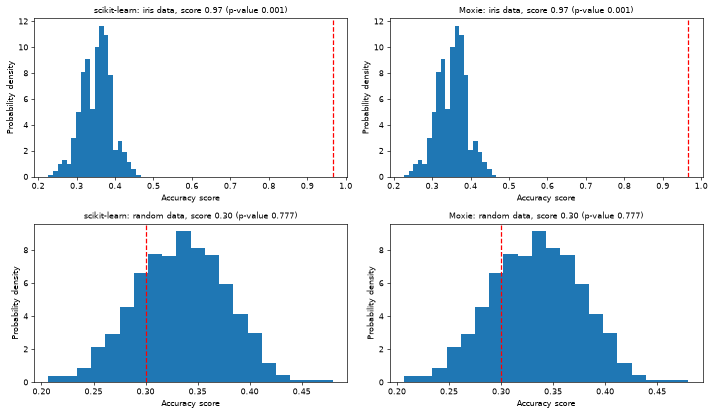

In [4]:
mx = nb.results["permutation"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
panels = [("iris", perm_scores_iris, score_iris, pvalue_iris), ("random", perm_scores_rand, score_rand, pvalue_rand)]
for row, (name, perm, score, pvalue) in enumerate(panels):
    key = "iris" if name == "iris" else "rand"
    mx_perm, (mx_score, mx_pvalue) = mx["permutation_scores_" + key], mx["observed_" + key]
    for col, (label, p, s, pv) in enumerate([("scikit-learn", perm, score, pvalue), ("Moxie", mx_perm, mx_score, mx_pvalue)]):
        ax = axes[row, col]
        ax.hist(p, bins=20, density=True)
        ax.axvline(s, ls="--", color="r")
        ax.set_title(f"{label}: {name} data, score {s:.2f} (p-value {pv:.3f})", fontsize=10)
        ax.set_xlabel("Accuracy score")
        ax.set_ylabel("Probability density")
plt.tight_layout()
plt.show()
moxie_nb.side_by_side(sklearn=perm_scores_iris[:12], moxie=mx["permutation_scores_iris"][:12])

In [5]:
reason = "accuracies are ratios of integer counts; identical permutations, folds and fitted SVCs"
nb.compare("iris score", [score_iris], mx["observed_iris"][:1], rtol=0, atol=1e-15, reason=reason)
nb.compare("iris pvalue", [pvalue_iris], mx["observed_iris"][1:], rtol=0, atol=1e-15,
           reason="(count + 1) / (n_permutations + 1) from identical counts")
nb.compare("iris permutation_scores", perm_scores_iris, mx["permutation_scores_iris"], rtol=0, atol=1e-15, reason=reason)
nb.compare("random score", [score_rand], mx["observed_rand"][:1], rtol=0, atol=1e-15, reason=reason)
nb.compare("random pvalue", [pvalue_rand], mx["observed_rand"][1:], rtol=0, atol=1e-15,
           reason="(count + 1) / (n_permutations + 1) from identical counts")
nb.compare("random permutation_scores", perm_scores_rand, mx["permutation_scores_rand"], rtol=0, atol=1e-15, reason=reason)
nb.note("cv splitter object", "ADAPTED",
        "re-stratification per permuted target is an explicit PermutationCV provider; fold lists stay fixed")
nb.note("scoring='accuracy'", "ADAPTED", "typed scorer struct; no string scorer lookup")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
iris score,PASS,"(1,)","(1,)",0,0,"rtol=0, atol=1e-15",,"accuracies are ratios of integer counts; identical permutations, folds and fitted SVCs"
iris pvalue,PASS,"(1,)","(1,)",0,0,"rtol=0, atol=1e-15",,(count + 1) / (n_permutations + 1) from identical counts
iris permutation_scores,PASS,"(1000,)","(1000,)",0,0,"rtol=0, atol=1e-15",,"accuracies are ratios of integer counts; identical permutations, folds and fitted SVCs"
random score,PASS,"(1,)","(1,)",0,0,"rtol=0, atol=1e-15",,"accuracies are ratios of integer counts; identical permutations, folds and fitted SVCs"
random pvalue,PASS,"(1,)","(1,)",0,0,"rtol=0, atol=1e-15",,(count + 1) / (n_permutations + 1) from identical counts
random permutation_scores,PASS,"(1000,)","(1000,)",0,0,"rtol=0, atol=1e-15",,"accuracies are ratios of integer counts; identical permutations, folds and fitted SVCs"
cv splitter object,ADAPTED,,,,,,re-stratification per permuted target is an explicit PermutationCV provider; fold lists stay fixed,
scoring='accuracy',ADAPTED,,,,,,typed scorer struct; no string scorer lookup,
